# Optimización de agentes en una mesa de ayuda con Reinforcement Learning

**Estudiante:** David Alonso Torres Rivas  
**Programa:** Especialización en Analítica y Ciencia de Datos  
**Asignatura:** Machine Learning  

**Proyecto académico | Q-Learning vs. SARSA vs. asignación fija**

Este cuaderno implementa un entorno empresarial **simulado** (no utiliza datos reales). Contiene diseño del problema, pruebas del entorno, entrenamiento, evaluación reproducible y visualizaciones.

**Pregunta:** ¿pueden Q-Learning y SARSA reducir el costo penalizado de asignar personal frente a una política fija de tres agentes?

**Limitación:** no se modela un SLA temporal ni la duración individual de tickets. Se penaliza la cola pendiente, no un incumplimiento de SLA.

## 1. Reglas y formulación

- Jornada: 8 intervalos de 30 minutos; cinco agentes disponibles; cada uno atiende hasta tres tickets por intervalo.
- Demanda esperada por intervalo: baja (3), media (7), alta (12); llegadas independientes Poisson, observadas **después** de decidir.
- Patrón: baja, baja, media, alta, alta, media, media, baja.
- Estado observado: `(intervalo, nivel_demanda, pendientes, agentes_actuales)`. Incluimos el intervalo para distinguir el horizonte restante.
- Acciones: `-1, 0, +1` agente; se excluyen las que violen los límites.
- La cola no tiene edades; las solicitudes se consideran homogéneas y se acumulan.
- Recompensa por paso: `-(10 * agentes_asignados + 5 * pendientes_al_cierre_del_intervalo)`; al final, penalización extra `-10 * pendientes_finales`.
- Se inicia con tres agentes. La política fija mantiene tres durante toda la jornada.

La variable de pendientes es exacta (sin discretizar) y puede crecer; usamos un diccionario de valores Q en vez de una matriz densa. Los parámetros económicos son unidades ficticias, no costos empresariales observados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

SEED = 42
DEMAND_LEVELS = (0, 0, 1, 2, 2, 1, 1, 0)
DEMAND_MEANS = (3, 7, 12)
ACTIONS = (-1, 0, 1)
print("NumPy:", np.__version__, "| Pandas:", pd.__version__)

NumPy: 1.26.4 | Pandas: 3.0.6


## 2. Entorno

La demanda de cada jornada se genera **por adelantado** con una semilla independiente de las decisiones. Así, distintas políticas reciben exactamente las mismas llegadas cuando se evalúan con la misma semilla. El agente no ve esas llegadas futuras.

In [2]:
class HelpDeskEnvironment:
    """Simulador discreto de asignación de agentes de soporte."""

    def __init__(self, seed=42, arrivals=None):
        self.max_agents = 5
        self.capacity_per_agent = 3
        self.max_steps = 8
        self.rng = np.random.default_rng(seed)
        self.arrivals_override = arrivals
        self.reset()

    def reset(self):
        """Reinicia el episodio y devuelve el estado inicial."""
        self.time = 0
        self.pending = 0
        self.agents = 3
        if self.arrivals_override is None:
            self.arrivals = tuple(int(self.rng.poisson(DEMAND_MEANS[level]))
                                  for level in DEMAND_LEVELS)
        else:
            if len(self.arrivals_override) != self.max_steps or any(
                int(x) != x or x < 0 for x in self.arrivals_override
            ):
                raise ValueError("Se requieren 8 llegadas enteras no negativas")
            self.arrivals = tuple(int(x) for x in self.arrivals_override)
        return self.get_state()

    def get_state(self):
        """Estado observable; None indica episodio finalizado."""
        if self.time >= self.max_steps:
            return None
        return (self.time, DEMAND_LEVELS[self.time], self.pending, self.agents)

    def valid_actions(self):
        """Acciones que mantienen los agentes en el rango permitido."""
        if self.time >= self.max_steps:
            return []
        return [a for a in ACTIONS if 0 <= self.agents + a <= self.max_agents]

    def step(self, action):
        """Aplica una decisión, simula atención y retorna (estado, recompensa, fin, info)."""
        if self.time >= self.max_steps:
            raise RuntimeError("El episodio ya terminó; llama a reset()")
        if action not in self.valid_actions():
            raise ValueError(f"Acción inválida: {action}")
        self.agents += action
        arrivals = self.arrivals[self.time]
        available = self.pending + arrivals
        attended = min(available, self.agents * self.capacity_per_agent)
        self.pending = available - attended
        cost_staff = 10 * self.agents
        cost_queue = 5 * self.pending
        self.time += 1
        done = self.time == self.max_steps
        cost_terminal = 10 * self.pending if done else 0
        reward = -(cost_staff + cost_queue + cost_terminal)
        info = dict(arrivals=arrivals, attended=attended, pending=self.pending,
                    agents=self.agents, cost_staff=cost_staff,
                    cost_queue=cost_queue, cost_terminal=cost_terminal)
        return self.get_state(), reward, done, info


def valid_actions_for_state(state, max_agents=5):
    """Máscara de acciones válidas a partir del estado observado."""
    agents = state[3]
    return [a for a in ACTIONS if 0 <= agents + a <= max_agents]


def greedy_action(q_table, state):
    """Elige la acción válida de mayor valor; empates favorecen mantener personal."""
    candidates = valid_actions_for_state(state)
    values = q_table[state]
    return max(candidates, key=lambda a: (values[a + 1], -abs(a), -a))


## 3. Pruebas de consistencia

Se verifican límites, conservación de tickets, cálculo de recompensas y finalización del episodio. Estas pruebas deben pasar **antes** de entrenar.

In [3]:
env = HelpDeskEnvironment(arrivals=[0]*8)
assert env.get_state() == (0, 0, 0, 3)
assert env.step(0)[1] == -30
assert env.pending == 0

# Sin agentes, nada se atiende; se conserva toda la demanda.
env = HelpDeskEnvironment(arrivals=[5]*8)
for a in (-1, -1, -1):
    _, _, _, info = env.step(a)
assert env.agents == 0 and env.pending == 7
assert info["attended"] == 0

# Jornada completa y conservación de solicitudes.
env = HelpDeskEnvironment(seed=SEED)
state = env.reset()
received = served = 0
while state is not None:
    state, reward, done, info = env.step(0)
    assert 0 <= info["attended"] <= info["agents"] * 3
    received += info["arrivals"]
    served += info["attended"]
assert done and received == served + env.pending
try:
    env.step(0)
    raise AssertionError("Debió impedirse avanzar tras finalizar")
except RuntimeError:
    pass
print("Todas las pruebas básicas pasaron.")

Todas las pruebas básicas pasaron.


## 4. Políticas y entrenamiento

Usamos `epsilon-greedy` con exploración decreciente, 10.000 episodios por algoritmo y actualización temporal con valor futuro cero al terminar. Q-Learning usa el máximo valor del siguiente estado; SARSA usa la **acción realmente elegida** para el siguiente estado. Se inicializan los valores Q en cero.

En los empates durante evaluación se prefiere mantener la asignación, para no introducir una preferencia arbitraria por reducir agentes.

In [4]:
def epsilon_greedy(q_table, state, epsilon, rng):
    """Selecciona una acción válida con exploración epsilon-greedy."""
    candidates = valid_actions_for_state(state)
    if rng.random() < epsilon:
        return int(rng.choice(candidates))
    return greedy_action(q_table, state)


def train_agent(algorithm, episodes=10_000, alpha=0.1, gamma=0.95,
                epsilon_start=1.0, epsilon_min=0.05, seed=42):
    """Entrena Q-Learning o SARSA y devuelve tabla Q e historial."""
    if algorithm not in ("q_learning", "sarsa"):
        raise ValueError("Algoritmo no soportado")
    rng = np.random.default_rng(seed)
    env = HelpDeskEnvironment(seed=seed + 1_000_000)
    q_table = defaultdict(lambda: np.zeros(3, dtype=float))
    history = []
    for episode in range(episodes):
        state = env.reset()
        epsilon = max(epsilon_min,
                      epsilon_start - (epsilon_start - epsilon_min) * episode / max(1, episodes - 1))
        total_reward = 0.0
        action = epsilon_greedy(q_table, state, epsilon, rng)
        done = False
        while not done:
            next_state, reward, done, _ = env.step(action)
            if done:
                target = reward
                next_action = None
            elif algorithm == "q_learning":
                target = reward + gamma * max(
                    q_table[next_state][a + 1] for a in valid_actions_for_state(next_state)
                )
                next_action = None
            else:
                next_action = epsilon_greedy(q_table, next_state, epsilon, rng)
                target = reward + gamma * q_table[next_state][next_action + 1]
            idx = action + 1
            q_table[state][idx] += alpha * (target - q_table[state][idx])
            total_reward += reward
            state = next_state
            if not done:
                action = (next_action if algorithm == "sarsa" else
                          epsilon_greedy(q_table, state, epsilon, rng))
        history.append(total_reward)
    return q_table, np.asarray(history)

q_table, q_rewards = train_agent("q_learning", seed=SEED)
sarsa_table, sarsa_rewards = train_agent("sarsa", seed=SEED)
print("Estados visitados Q-Learning:", len(q_table))
print("Estados visitados SARSA:", len(sarsa_table))
print("Recompensa media de los últimos 100 episodios:",
      round(q_rewards[-100:].mean(), 2), round(sarsa_rewards[-100:].mean(), 2))

Estados visitados Q-Learning: 858
Estados visitados SARSA: 857
Recompensa media de los últimos 100 episodios: -331.75 -297.75


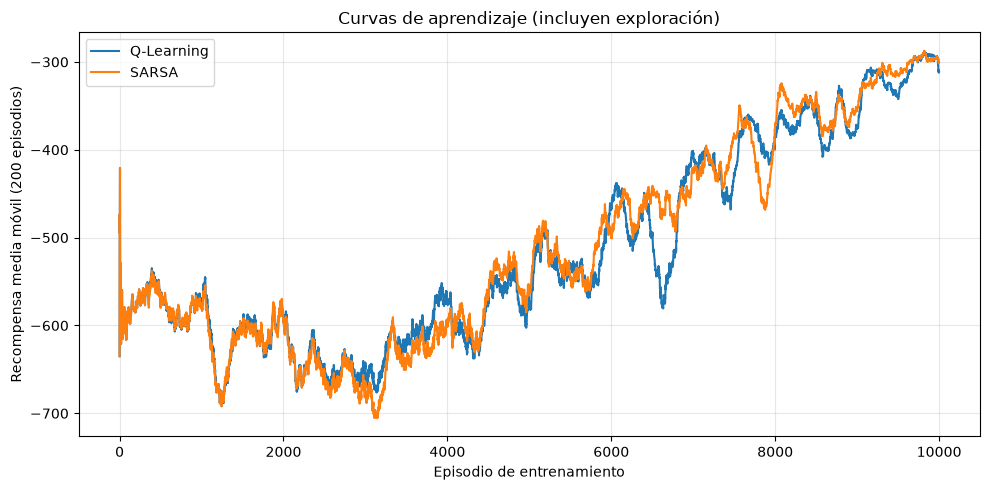

In [5]:
plt.figure(figsize=(10, 5))
for label, values in [("Q-Learning", q_rewards), ("SARSA", sarsa_rewards)]:
    smooth = pd.Series(values).rolling(200, min_periods=1).mean()
    plt.plot(smooth, label=label)
plt.xlabel("Episodio de entrenamiento")
plt.ylabel("Recompensa media móvil (200 episodios)")
plt.title("Curvas de aprendizaje (incluyen exploración)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Evaluación fuera del entrenamiento

Se evalúan las tres estrategias en **1.000 jornadas de prueba**, con las mismas llegadas por semilla. Se reportan recompensa, costos de personal, cola acumulada, tickets pendientes, proporción atendida y agentes-intervalo. La política fija usa tres agentes; las políticas RL se ejecutan sin exploración.

La recompensa es el negativo del costo penalizado; por ello **mayor recompensa (menos negativa) es mejor**. La tasa de atención y los pendientes se interpretan por separado para evitar conclusiones engañosas.

In [6]:
def evaluate_one(policy, arrivals, q_table=None):
    """Evalúa una jornada usando llegadas fijadas externamente."""
    env = HelpDeskEnvironment(arrivals=arrivals)
    state = env.reset()
    metrics = dict(reward=0.0, arrivals=0, attended=0, pending=0,
                   agent_intervals=0, staff_cost=0, queue_cost=0, terminal_cost=0)
    allocation = []
    while state is not None:
        action = 0 if policy == "Fija" else greedy_action(q_table, state)
        state, reward, done, info = env.step(action)
        metrics["reward"] += reward
        for key in ("arrivals", "attended", "agent_intervals", "staff_cost", "queue_cost", "terminal_cost"):
            source = {"agent_intervals": "agents"}.get(key, "cost_" + key.replace("_cost", "") if key.endswith("_cost") else key)
            metrics[key] += info[source]
        allocation.append(info["agents"])
    metrics["pending"] = env.pending
    metrics["service_rate"] = (metrics["attended"] / metrics["arrivals"]
                               if metrics["arrivals"] else 1.0)
    metrics["allocation"] = allocation
    return metrics

records = []
for test_seed in range(10_000, 11_000):
    arrivals = tuple(int(x) for x in np.random.default_rng(test_seed).poisson(
        [DEMAND_MEANS[level] for level in DEMAND_LEVELS]
    ))
    for policy, table in [("Fija", None), ("Q-Learning", q_table), ("SARSA", sarsa_table)]:
        result = evaluate_one(policy, arrivals, table)
        records.append({"seed": test_seed, "policy": policy, **result})
results = pd.DataFrame(records)
assert (results.groupby("seed")["arrivals"].nunique() == 1).all()
assert (results["arrivals"] == results["attended"] + results["pending"]).all()
assert np.allclose(results["reward"], -(
    results["staff_cost"] + results["queue_cost"] + results["terminal_cost"]
))
summary = results.groupby("policy")[["reward", "staff_cost", "queue_cost", "terminal_cost",
                                     "pending", "agent_intervals", "service_rate"]].agg(["mean", "std"])
display(summary.round(3))

reward          staff_cost         queue_cost           \
               mean      std       mean     std       mean      std   
policy                                                                
Fija       -362.580  113.812     240.00   0.000    109.640   90.271   
Q-Learning -382.190  235.383     207.73  36.629    148.380  184.244   
SARSA      -283.555   97.627     240.43  17.176     39.425   79.397   

           terminal_cost         pending        agent_intervals         \
                    mean     std    mean    std            mean    std   
policy                                                                   
Fija               12.94  27.766   1.294  2.777          24.000  0.000   
Q-Learning         26.08  78.891   2.608  7.889          20.773  3.663   
SARSA               3.70  27.189   0.370  2.719          24.043  1.718   

           service_rate         
                   mean    std  
policy                          
Fija              0.980  0.041  
Q-Learning        0.955  0.134  
SARSA             0.994  0.042

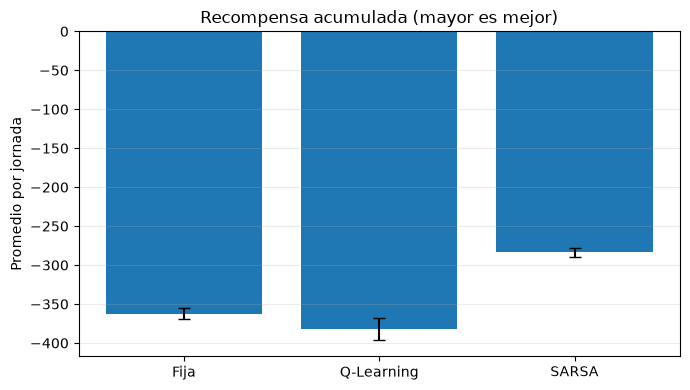

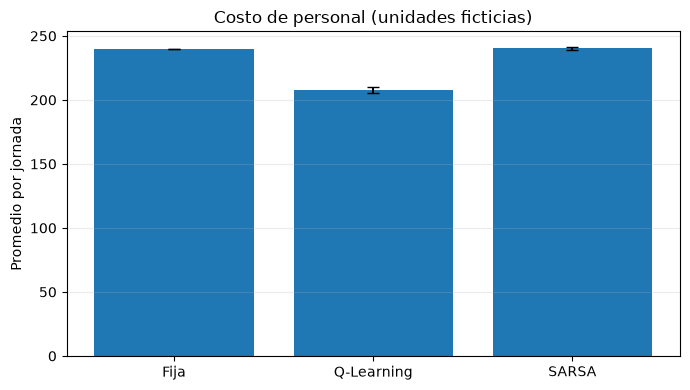

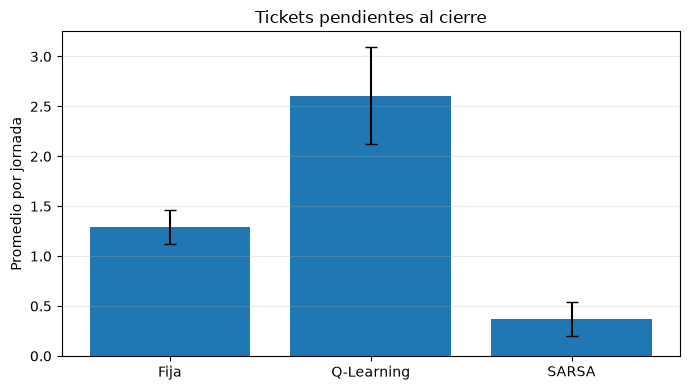

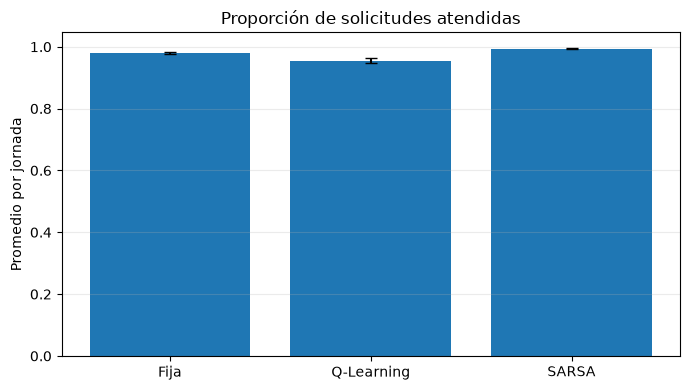

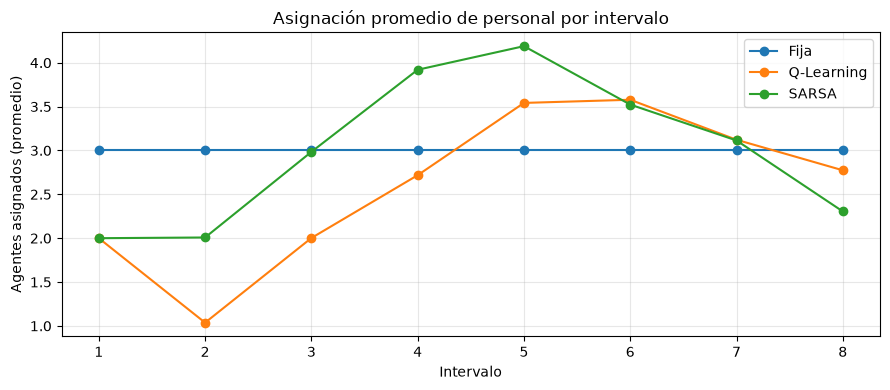

In [7]:
metrics_to_plot = {
    "reward": "Recompensa acumulada (mayor es mejor)",
    "staff_cost": "Costo de personal (unidades ficticias)",
    "pending": "Tickets pendientes al cierre",
    "service_rate": "Proporción de solicitudes atendidas"
}
for metric, title in metrics_to_plot.items():
    means = results.groupby("policy")[metric].mean().reindex(["Fija", "Q-Learning", "SARSA"])
    errors = results.groupby("policy")[metric].sem().reindex(means.index) * 1.96
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(means.index, means.values, yerr=errors.values, capsize=4)
    ax.set_title(title)
    ax.set_ylabel("Promedio por jornada")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()

allocations = np.array(results["allocation"].tolist())
fig, ax = plt.subplots(figsize=(9, 4))
for policy in ("Fija", "Q-Learning", "SARSA"):
    arr = np.array(results.loc[results.policy == policy, "allocation"].tolist())
    ax.plot(np.arange(1, 9), arr.mean(axis=0), marker="o", label=policy)
ax.set(xlabel="Intervalo", ylabel="Agentes asignados (promedio)",
       title="Asignación promedio de personal por intervalo")
ax.set_xticks(range(1, 9))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
robustness = []
for training_seed in [11, 22, 33, 44, 55]:
    for algorithm, label in [("q_learning", "Q-Learning"), ("sarsa", "SARSA")]:
        table, _ = train_agent(algorithm, seed=training_seed)
        for test_seed in range(20_000, 20_200):
            arrivals = np.random.default_rng(test_seed).poisson(
                [DEMAND_MEANS[level] for level in DEMAND_LEVELS]
            )
            result = evaluate_one(label, arrivals, table)
            robustness.append({"train_seed": training_seed, "policy": label,
                               "reward": result["reward"], "pending": result["pending"]})
robustness_df = pd.DataFrame(robustness)
per_training = robustness_df.groupby(["policy", "train_seed"])[["reward", "pending"]].mean()
display(per_training.round(2))
print("Variabilidad entre entrenamientos:")
display(per_training.groupby("policy").agg(["mean", "std"]).round(2))

reward  pending
policy     train_seed                 
Q-Learning 11         -282.45     0.12
           22         -285.90     0.23
           33         -280.88     0.32
           44         -306.85     0.47
           55         -298.60     0.27
SARSA      11         -281.18     0.10
           22         -277.75     0.06
           33         -285.00     0.24
           44         -282.98     0.32
           55         -281.58     0.26

Variabilidad entre entrenamientos:


reward        pending      
              mean    std    mean   std
policy                                 
Q-Learning -290.94  11.30    0.28  0.13
SARSA      -281.70   2.67    0.19  0.11

## 6. Robustez y discusión

La comparación anterior utiliza **una sola tabla entrenada por algoritmo**. Para analizar variabilidad del aprendizaje, repetimos el entrenamiento con cinco semillas y evaluamos cada modelo sobre las mismas jornadas de prueba. Se muestran medias entre entrenamientos, sin confundirlas con 5.000 observaciones independientes de entrenamiento.

**Preguntas:**

**1. ¿Cuál política obtiene mayor recompensa en las jornadas de prueba?**
   
De acuerdo con los resultados obtenidos en las 1.000 jornadas de evaluación, SARSA presenta la mayor recompensa acumulada promedio, seguido de la política fija y finalmente Q-Learning.
   
**2. ¿La mejora de costos se acompaña de más solicitudes pendientes?**

Los resultados muestran que reducir el costo de personal no necesariamente mejora el desempeño general del sistema. Q-Learning consigue reducir el costo de personal aproximadamente un 13,4 % frente a la política fija. Sin embargo, esta reducción viene acompañada de un aumento en las solicitudes pendientes y de mayores penalizaciones.

Por su parte, SARSA mantiene un costo de personal similar al de la política fija, pero logra disminuir considerablemente las solicitudes pendientes.

Esto evidencia que la estrategia más económica en términos de personal no siempre es la más eficiente para la empresa. Es necesario considerar simultáneamente el costo operativo y la calidad de atención.
   
**3. ¿Las curvas de entrenamiento sugieren estabilización? ¿Es suficiente para afirmar convergencia?**

Las curvas de entrenamiento permiten observar la evolución de las recompensas obtenidas por Q-Learning y SARSA a medida que los agentes interactúan con el entorno.

En los últimos 100 episodios, Q-Learning obtuvo una recompensa promedio de -331,75, mientras que SARSA alcanzó -297,75. Estos resultados indican que SARSA presentó un mejor desempeño durante la etapa final del entrenamiento analizado.

Sin embargo, no es suficiente observar una curva aparentemente estable para afirmar que los algoritmos han convergido.

Las recompensas pueden fluctuar debido a la variabilidad de la demanda, las decisiones exploratorias y las actualizaciones de la tabla Q. Además, una recompensa estable no garantiza que se haya encontrado la política óptima.

Para evaluar la convergencia con mayor rigor, sería necesario analizar la estabilidad de los valores Q, comprobar si las decisiones aprendidas dejan de cambiar y repetir los entrenamientos con diferentes semillas.

Por tanto, las curvas pueden aportar indicios de estabilización, pero no constituyen una demostración formal de convergencia.

**4. ¿Qué cambia entre semillas? ¿Las diferencias entre algoritmos son consistentes?**

Las semillas aleatorias influyen en la generación de solicitudes durante el entrenamiento y en las decisiones exploratorias de los algoritmos. Por esta razón, diferentes semillas pueden producir distintas políticas aprendidas.

Para evaluar esta variabilidad, se realizaron cinco entrenamientos independientes por algoritmo.

Los resultados muestran que SARSA obtiene una recompensa promedio superior y presenta menor variabilidad entre entrenamientos.

No obstante, la diferencia no es completamente consistente: con la semilla 33, Q-Learning supera a SARSA.

Esto permite concluir que SARSA mostró un comportamiento más estable en los experimentos realizados, aunque no podemos afirmar que siempre sea superior.

También se observa que Q-Learning presenta mayor sensibilidad a la semilla utilizada. Por ello, evaluar un algoritmo con un único entrenamiento puede conducir a conclusiones poco representativas.
   
**5. ¿Cómo afectan los supuestos (demanda Poisson, capacidad constante, ausencia de SLA) a la aplicabilidad real?**

El entorno desarrollado utiliza varios supuestos que permiten simplificar el problema y facilitar la implementación de los algoritmos de aprendizaje por refuerzo.

Demanda Poisson: permite simular llegadas aleatorias de solicitudes según diferentes niveles de demanda. Sin embargo, en una mesa de ayuda real pueden presentarse incidentes masivos, eventos extraordinarios y patrones de llegada que no se ajusten a esta distribución.

Capacidad constante: el modelo supone que todos los agentes pueden atender tres solicitudes por intervalo, independientemente de la complejidad del caso. En la práctica, los tiempos de resolución varían según la experiencia del agente, la prioridad y la dificultad de cada solicitud.

Ausencia de SLA: el modelo penaliza las solicitudes pendientes, pero no controla directamente los tiempos máximos de atención ni distingue entre solicitudes urgentes y no urgentes. Esto limita su capacidad para representar compromisos reales de calidad del servicio.

En consecuencia, los resultados son válidos dentro de las condiciones del entorno simulado, pero no pueden extrapolarse directamente a una empresa real.

Para una aplicación empresarial sería necesario incorporar datos históricos, tiempos variables de atención, prioridades y acuerdos de nivel de servicio. También sería importante validar el comportamiento del modelo antes de utilizarlo para tomar decisiones operativas.


## 7. Conclusiones

Los experimentos permiten evidenciar que el aprendizaje por refuerzo puede utilizarse para optimizar la asignación de recursos en una mesa de ayuda de soporte técnico.

En la evaluación principal, SARSA obtuvo mejores resultados que Q-Learning y la política fija, principalmente porque logró reducir la acumulación de solicitudes sin incrementar significativamente los costos de personal.

Q-Learning, aunque consiguió disminuir el costo operativo, presentó mayores penalizaciones asociadas a solicitudes pendientes, demostrando la importancia de equilibrar los diferentes componentes de la función de recompensa.

Adicionalmente, las pruebas con distintas semillas mostraron que los resultados dependen del proceso de entrenamiento y que SARSA presentó mayor estabilidad en los experimentos realizados.

Finalmente, el proyecto permitió comprender la aplicación de los principales componentes del aprendizaje por refuerzo: estados, acciones, recompensas, exploración y aprendizaje de políticas. Aunque el entorno representa una versión simplificada de una operación empresarial, constituye una base para desarrollar modelos más realistas.

### Reproducibilidad

- Requisitos: Python 3.10+, `numpy`, `pandas`, `matplotlib`, `ipykernel` (para Jupyter).
- Todas las semillas y parámetros están explícitos.
- En GitHub incluir este `.ipynb`, `README.md` con instrucciones y `requirements.txt` con versiones utilizadas.
- El informe PDF debe identificar a los tres integrantes, sus aportes, las métricas y el enlace real al repositorio.

### Referencias bibliográficas

- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement learning: An introduction* (2nd ed.). MIT Press.
- Watkins, C. J. C. H., & Dayan, P. (1992). Q-learning. *Machine Learning, 8*, 279–292.
- Rummery, G. A., & Niranjan, M. (1994). *On-line Q-learning using connectionist systems* (Technical Report CUED/F-INFENG/TR 166). University of Cambridge.
